<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/6.%20Attention%20mechanism/3.%20Simple%20MHA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Training a simple Multi Head Attention

- we will train a Multi Head attentin model that when given an Image, it will try to find an image in the given dataset (100 images) that closely matches it!!
- Meaning, we will train the model on the whole dataset, but we will generate the weighted sum over the small dataset of 100 images and see how the softmax assigns the probabilities of similarities of the 100 dataset images.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.utils.data.dataloader as dataloader

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from pathlib import Path

In [2]:
# We start by downloading the dataset and take 100 datapoints randomly just like
# our previous notebook.
data_dir = Path("../assets/datasets")  # I'm just using the previous path from codespaces.

# we will select only 100 images to work with in this tutorial
n_images = 100

#we define a transfor to normalise and convert to tensor while downloading our dataset.
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.1307],[0.3081])   # since we know our mean and std from earlier notebooks
])

#Load our dataset.
dataset = datasets.MNIST(
    data_dir,
    train = True,
    transform=image_transform,
    download=True
)

In [3]:
# select random indices from our dataset.
rand_idx = torch.randint(dataset.data.shape[0], (n_images,))
# print(rand_idx)

#extract the images and concatnate them into a single tensor.
dataset_tensor = torch.cat([dataset.data[i].unsqueeze(0).reshape(1,-1) for i in rand_idx])

In [4]:
dataset_tensor.data.shape

torch.Size([100, 784])

## Architecture

- In the notebook before, we have the query, key and value vectors initiated randomly and with the necessary embedding dimensions.
- Here we have images, and we need to some how introduce non linearity and embed them before passing them through the MHA layer.
- So, we will use a MLP layer as an input.
  - We will put two linear layers , a layer normalization, and an activation function between them
  - We will wrap these four layers inside a nn.Sequential layer to pass the input images through eachother with out explicitly saying that in forward pass.
- Then we will initilize the MHA layer.

In [5]:
class TestingAttention(nn.Module):
  def __init__(self, num_heads, emb_dim):
    super(TestingAttention, self).__init__()

    #define the MLP block
    self.mlp = nn.Sequential(
        nn.Linear(in_features= 784, out_features=emb_dim),
        nn.LayerNorm(emb_dim),
        nn.ELU(),
        nn.Linear(in_features=emb_dim, out_features=emb_dim)
    )

    #define the MHA layer
    self.mha = nn.MultiheadAttention(num_heads = num_heads, embed_dim=emb_dim, batch_first = True)

  def forward(self, img, values):
    '''
    img - Image instance from the whole dataset. Used as Query for our problem
    value - These are the images of batch_size from our 100 datapoints. Used as keys and Values for our problem
    '''
    #pass both the image and value through mlp
    img_ = self.mlp(img)    #the variable is changed in the runtime only
    values_ = self.mlp(values)

    # MHA layer
    attention_score, attention_weight = self.mha(query = img_, key = values_, value = values_)

    # Once we got the attention weights (softmax(Q@K.T/(d_k^0.5))), we can perform matmul with values
    #to scale the output
    output = torch.bmm(attention_weight, values)

    return attention_weight, output





In [6]:
# define the hyperparameters
bs = 32

num_heads = 1

emb_size = 512

nepochs = 10

#define the device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [7]:
from torch.utils.data import DataLoader
#we can now create our dataloader
train_loader = dataloader.DataLoader(
    dataset = dataset,
    batch_size= bs,
    shuffle=True,
    num_workers=3,
    drop_last=True
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [8]:
# Initilize our model, loss and optimizer

similarity_model = TestingAttention(num_heads=num_heads, emb_dim=emb_size).to(device)
print(similarity_model)

loss_fn = nn.MSELoss()

optimizer = optim.Adam(params=similarity_model.parameters(), lr=0.001)

TestingAttention(
  (mlp): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): ELU(alpha=1.0)
    (3): Linear(in_features=512, out_features=512, bias=True)
  )
  (mha): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
  )
)


In [9]:
loss_logger = []

In [10]:
#for every batch during the training, we need a value tensor to be passed for the forward pass
# so, we can use our 100 datapoint dataset tensor, to math the dimensions of input image and expand to the batch size
dataset_tensor.unsqueeze(0).shape #and expand this to make pointers that refer to this dataset for all batches

value_tensors = dataset_tensor.unsqueeze(0).expand(bs, n_images, -1).to(device)

# this is the value_tensor we pass to the forward pass with each mini batch during trainig


In [11]:
data, lab = next(iter(train_loader))

print(data.shape)
print(lab.shape)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


torch.Size([32, 1, 28, 28])
torch.Size([32])


In [12]:
#train loop

similarity_model.train()
steps = 0

for epoch in tqdm(range(nepochs), desc = 'epochs', leave = False):
  b_l = 0
  #mini batches
  for data, label in tqdm(train_loader, desc = 'Training', leave = False):

    optimizer.zero_grad()

    # reshape the data to match the model requirements from (bs, 1, 28,28) (bs, 1, features)
    query = data.reshape(bs, 1, -1).to(device)
    #forwardpass
    att_weight, att_out = similarity_model(query, value_tensors.float())

    #calculate loss
    loss = loss_fn(att_out, query)

    #append loss
    #loss_logger.append(loss.item())
    b_l += loss.item()

    #set the backprop
    loss.backward()
    optimizer.step()
  steps += bs
  batch_loss = b_l/steps
  loss_logger.append(batch_loss)
print(f'Finished training {nepochs} epochs')

epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/1875 [00:00<?, ?it/s]

Training:   0%|          | 0/1875 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Training:   0%|          | 0/1875 [00:00<?, ?it/s]

Training:   0%|          | 0/1875 [00:00<?, ?it/s]

... (3 outputs left out)

Training:   0%|          | 0/1875 [00:00<?, ?it/s]

Training:   0%|          | 0/1875 [00:00<?, ?it/s]

Training:   0%|          | 0/1875 [00:00<?, ?it/s]

Finished training 10 epochs


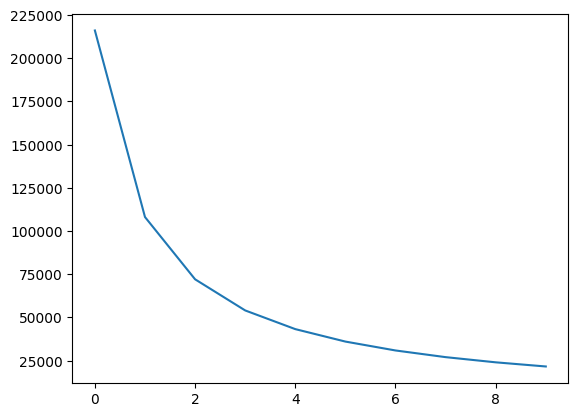

In [13]:
#plot the loss
plt.plot(loss_logger)

## Evaluation

In [14]:
data, lab = next(iter(train_loader))

print(data.shape)
print(lab.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


In [15]:
similarity_model.eval()

with torch.no_grad():
  q_image = data.reshape(bs, 1, -1).to(device)

  attn_weight, op = similarity_model(q_image, value_tensors.float())

## Using the model

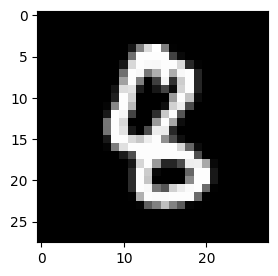

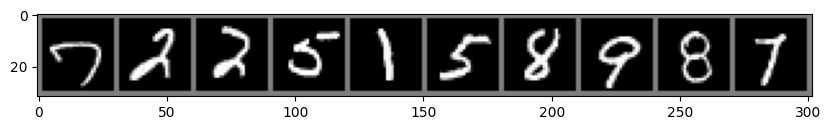

In [16]:
index = 10

# Plot the original image
plt.figure(figsize=(3, 3))
out = torchvision.utils.make_grid(q_image[index].cpu().reshape(-1, 1, 28, 28), 8,
                                  normalize=True, pad_value=0.5)
plt.imshow(out.numpy().transpose((1, 2, 0)))

# For a given input, use the attention map to find the "closest" value-data matches
top10 = attn_weight[index, 0].argsort(descending=True)[:10]
top10_data = value_tensors[index, top10].float().cpu()

# Plot the top 10 closest matches
plt.figure(figsize=(10, 10))
out = torchvision.utils.make_grid(top10_data.reshape(-1, 1, 28, 28), 10, normalize=True, pad_value=0.5)
plt.imshow(out.numpy().transpose((1, 2, 0)))

- Not a great result but may be if we keep training the model since the loss is still going down, out result might be better.
- better in the sence, the images with letter 8 in our dataset gets more weight than other numbers.